In [14]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Load a model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loaded_model = torch.load("model_shape_prediction.pth")
loaded_model.to(device)

# Load a data as input (phases) to get shapes
phase_input = np.load('phases.npy')

/tmp/ipykernel_40713/2432359938.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_model = torch.load("model_shape_prediction.pth")


In [15]:
type(phase_input)

numpy.ndarray

In [16]:
print(phase_input[:10])

[-1.04719755 -3.28862304 -5.49665181 -1.40017351 -3.57625173 -5.75097672
 -1.64898746 -3.84299444 -6.060026   -2.03066867]


In [17]:
# Exchange numpy data for torch
phase_input = torch.tensor(phase_input, dtype=torch.float32).to(device)  # Convert to tensor and move to the correct device
print(phase_input)

tensor([-1.0472, -3.2886, -5.4967, -1.4002, -3.5763, -5.7510, -1.6490, -3.8430,
        -6.0600, -2.0307, -4.2843, -0.2547, -2.5525, -4.8691, -0.9151, -3.2501,
        -5.5821, -1.6175, -3.9100, -6.2760, -2.4211, -4.7963, -0.8145, -3.3250,
        -5.7364, -1.8560, -4.3622, -0.4594, -3.0259, -5.4493, -1.7377, -4.2482,
        -0.4646, -3.0837, -5.6365, -1.8678, -4.5313, -0.9008, -3.5453, -6.1958,
        -2.5795, -5.2692, -1.7014, -4.4408, -0.9155, -3.6817, -0.1585, -2.9324,
        -5.8321, -2.4023, -5.2229, -1.9102, -4.7469, -1.5000, -4.4269, -1.1600,
        -4.2145, -0.9653, -4.0089, -0.8015, -3.9501, -0.8254, -4.0426, -1.0241,
        -4.3061, -1.2904, -4.6121, -1.7205, -5.0974, -2.2523, -5.7617, -2.9913,
        -0.2582, -3.8637, -1.2430, -4.9462, -2.3716, -6.1982, -3.7439, -1.4007,
        -5.3568, -3.0917, -0.9059, -5.0691, -2.9675, -1.0281, -5.3805, -3.5383,
        -1.8175, -0.1984, -4.8875, -3.4831, -2.1530, -0.9080, -6.1499, -5.2012,
        -4.4138, -3.7518, -3.2969, -3.08

### Fine! We have prepared everything for filling in
1. Now, we will calculate shapes according vectors off phase dalay
2. For that let's turn on eval mode for prediction model and then will get shapes as output wise-element.
3. Every output will be saved into new vectors - vector of shape coefficients.

In [18]:
print(phase_input.size())
print(phase_input[:10])
print(phase_input.ndim)
print(phase_input.device)

torch.Size([113])
tensor([-1.0472, -3.2886, -5.4967, -1.4002, -3.5763, -5.7510, -1.6490, -3.8430,
        -6.0600, -2.0307], device='cuda:0')
1
cuda:0


In [19]:
# We determine the dimensions
num_samples = phase_input.size(0)  # Number of rows (iterations)
output_dim = loaded_model(phase_input[0].unsqueeze(0)).size(0)  # Prediction size (second index)

In [20]:
output_dim

2

In [21]:
# Creating an empty matrix to store the results
output = torch.zeros((num_samples, output_dim), device=device)

In [22]:
output[:10]

tensor([[0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.]], device='cuda:0')

In [23]:
# Setting the evaluation mode
phase_input = phase_input.to(device)
loaded_model.eval()

# We get predictions and fill in the matrix
with torch.no_grad():
    for i in range(num_samples):
        print(f"Value of phase_input {i} is {phase_input[i]}")
        prediction = loaded_model(phase_input[i].unsqueeze(0))
        print(f"Prediction for {i} is {prediction}")
        output[i] = prediction.squeeze(0)  # Saving the prediction string

# Checking the output data
print("Model output data:", output[:10]) # under the zero index in the vector is the width, under the first index is the coefficient a


Value of phase_input 0 is -1.0471975803375244
Prediction for 0 is tensor([5.1543, 7.6377], device='cuda:0')
Value of phase_input 1 is -3.288623094558716
Prediction for 1 is tensor([1.6437, 2.4773], device='cuda:0')
Value of phase_input 2 is -5.496651649475098
Prediction for 2 is tensor([-0.4104, -0.5433], device='cuda:0')
Value of phase_input 3 is -1.400173544883728
Prediction for 3 is tensor([4.5297, 6.7209], device='cuda:0')
Value of phase_input 4 is -3.576251745223999
Prediction for 4 is tensor([1.2993, 1.9710], device='cuda:0')
Value of phase_input 5 is -5.7509765625
Prediction for 5 is tensor([-0.5717, -0.7805], device='cuda:0')
Value of phase_input 6 is -1.6489874124526978
Prediction for 6 is tensor([4.0935, 6.0799], device='cuda:0')
Value of phase_input 7 is -3.842994451522827
Prediction for 7 is tensor([1.0024, 1.5343], device='cuda:0')
Value of phase_input 8 is -6.060026168823242
Prediction for 8 is tensor([-0.7511, -1.0444], device='cuda:0')
Value of phase_input 9 is -2.03066

Ready! We have created a tensor that describes the shape of the cells at a given point.
Now we have a shape and we have centers. It remains to recalculate the coordinates for the atoms at these points.

In [24]:
width_matrix = []
a_matrix = []

# Divide the vector into parts, we will extract the elements.
for i in range (num_samples) :
    width_matrix.append(output[i,0].item())
    a_matrix.append(output[i,1].item())
    
print(width_matrix[:10])
print(a_matrix[:10])

[5.15425443649292, 1.6436662673950195, -0.41035622358322144, 4.529659271240234, 1.2993459701538086, -0.5716606974601746, 4.0935211181640625, 1.002415657043457, -0.751137912273407, 3.4521992206573486]
[7.637650489807129, 2.477323055267334, -0.5432827472686768, 6.720940589904785, 1.9709721803665161, -0.780493974685669, 6.07988166809082, 1.5343124866485596, -1.0444300174713135, 5.136890411376953]


In [25]:
#Let's start filling in
center_points = np.load('points.npy')
print(center_points[:10])
print(center_points[:,0])

[[ 46.5          0.        ]
 [ 45.21532151   9.89771489]
 [ 41.84277737  19.28983145]
 [ 36.52961067  27.73633724]
 [ 29.51658646  34.83488362]
 [ 21.12903826  40.24103601]
 [ 11.76340688  43.68648621]
 [  1.86972637  44.99418973]
 [ -8.06913841  44.08898784]
 [-17.56024699  41.00415324]]
[ 4.65000000e+01  4.52153215e+01  4.18427774e+01  3.65296107e+01
  2.95165865e+01  2.11290383e+01  1.17634069e+01  1.86972637e+00
 -8.06913841e+00 -1.75602470e+01 -2.61279760e+01 -3.33364145e+01
 -3.88086128e+01 -4.22561690e+01 -4.34908512e+01 -4.24379368e+01
 -3.91428237e+01 -3.37712683e+01 -2.66030793e+01 -1.80149209e+01
 -8.47742536e+00  1.47910838e+00  1.12997714e+01  2.04154068e+01
  2.83055774e+01  3.45016783e+01  3.86195800e+01  4.04218150e+01
  3.97580969e+01  3.66852819e+01  3.13534947e+01  2.41005706e+01
  1.53680291e+01  5.70324419e+00 -4.26769506e+00 -1.38969929e+01
 -2.25347946e+01 -2.95971400e+01 -3.45936711e+01 -3.71653295e+01
 -3.71152999e+01 -3.44291718e+01 -2.92826060e+01 -2.2035086

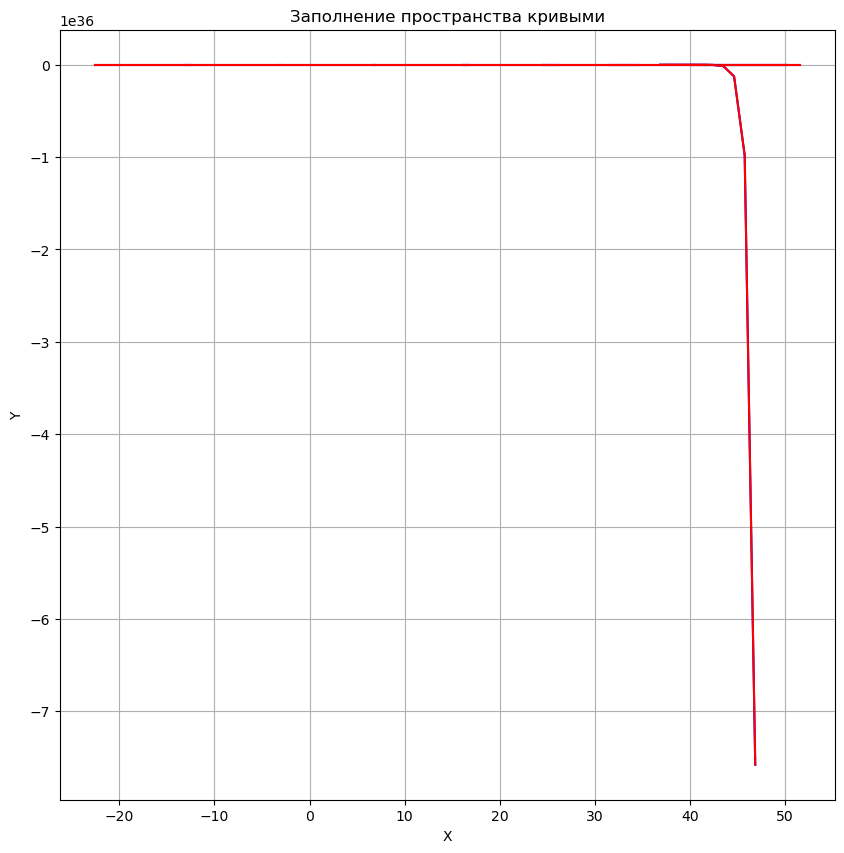

In [29]:
# Chain line parameters
x_shift = 5  # диапазон x
num_points = 10  # количество точек

# Creating a graph
plt.figure(figsize=(10, 10))

# Next wise-elements operations
for i in range(10):
    x = np.linspace(center_points[i,0] - x_shift, center_points[i,0] + x_shift, num_points)
    y_top = center_points[i,1] + (a_matrix[i] * np.cosh(x / a_matrix[i]))  # top
    y_bottom = center_points[i,1] + (y_top - width_matrix[i]) # bottom curve 
    
    plt.plot(x, y_top, color='blue')
    plt.plot(x, y_bottom, color='red')

plt.title("Filling space with curves")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.show()

And it doesn't really work, because it's necessary to fill in meta-atoms of this form using a different algorithm, but the principle is this.

I implemented such a filling with these curves using a different logic in my next program. 
And I will use the logic of working with meta-atoms described here for another type of cell, for which there is no need to find an analytical solution.